# Módulo 2 — Punto 2.1: Segmentación de la pupila

**Objetivo:**
Aislar de forma robusta la estructura de la pupila en el frame de trabajo y extender el algoritmo a través del tiempo.

Toda la lógica del cálculo está en `src/modulo2/segmentacion.py`; este notebook se encarga de llamar a los módulos y visualizar los resultados.

## 0. Configuración del entorno e importaciones
Se configura la ruta raíz del repositorio y se importan las librerías necesarias.

In [1]:
# --- Imports de la librería estándar ---
import sys                 
from pathlib import Path   

# --- Configurar la raíz del repositorio ---
# Path.cwd() = carpeta desde donde corre el notebook (normalmente notebooks/).
# Subimos carpetas hasta encontrar config.yaml: esa es la raíz.
# Así funciona tanto si VS Code abre el notebook desde notebooks/ como desde la raíz.
raiz = Path.cwd()
while not (raiz / "config.yaml").exists():
    if raiz.parent == raiz:          # llegamos a "/" sin encontrarlo
        raise FileNotFoundError("No encontré config.yaml en ninguna carpeta superior.")
    raiz = raiz.parent

# Insertamos la raíz al principio de sys.path (posición 0 = máxima prioridad).
if str(raiz) not in sys.path:
    sys.path.insert(0, str(raiz))

# --- Imports de terceros y propios
import numpy as np                 
import matplotlib.pyplot as plt    
import matplotlib.patches as patches  
import skimage as ski
import cv2 
from matplotlib.colors import ListedColormap

from src.config import cargar_config
from src.modulo1 import carga_muestreo as cm   
from src.modulo1 import calidad_filtrado as cf
from src.modulo2 import segmentacion as seg

from IPython.display import display, HTML
display(HTML("<style>.output_png { display: flex; justify-content: center; }</style>"))




## 1. Carga de Datos y Configuración Global
Se leen los parámetros desde `config.yaml`, se definen las rutas de salida e inicializan las imágenes de trabajo.

In [2]:
# Cargar configuración global
cfg = cargar_config(raiz / "config.yaml")

# Directorio de salida de resultados
carpeta_res = raiz / "results" / "modulo2"
carpeta_res.mkdir(parents=True, exist_ok=True)

# Carga de imagen y extracción de la ROI
img = cm.obtener_frame(cfg, raiz)
roi = cm.recortar_roi(img, cfg["roi"]) 
roi_grises = cf.conv_grises(roi) 

# Parámetros del módulo 1.2
p = cfg["modulo1_2"]
k = p["kernel"] #--> tamaño del kernel para filtrado
clahe_clip = p["clahe_clip"] #--> clip para CLAHE
clahe_grilla = p["clahe_grilla"] #--> tamaño de la grilla para CLAHE
sigma=p["gauss_sigma"]


# Parámetros del módulo 2
n = cfg["modulo2"]["snake"]
factor_radio_inicial = n["factor_radio_inicial"]
k=n["suavizado_k"]
sigma=n["suavizado_sigma"]
alpha=n["alpha"]
beta=n["beta"]
gamma=n["gamma"]

w = cfg["modulo2"]["watershed"]
factor_interior= w["factor_interior"]
factor_anillo_interior= w["factor_anillo_interior"]
factor_anillo_exterior= w["factor_anillo_exterior"]

km = cfg["modulo2"]["kmeans"]
factor_ventana=km["factor_ventana"]


print(f"Resultados en: {carpeta_res}")

Resultados en: c:\Users\ronal\Documents\Q2 2026\PSIB\Guia_Ojo\Guia-de-imagenes-biomedicas-G9-PSIB\results\modulo2


In [3]:
print("Raíz del proyecto:", raiz)
print("Ruta configurada:", cfg["salida"])
print("Carpeta de resultados:", carpeta_res.resolve())

Raíz del proyecto: c:\Users\ronal\Documents\Q2 2026\PSIB\Guia_Ojo\Guia-de-imagenes-biomedicas-G9-PSIB
Ruta configurada: {'carpeta_resultados': 'results/modulo1'}
Carpeta de resultados: C:\Users\ronal\Documents\Q2 2026\PSIB\Guia_Ojo\Guia-de-imagenes-biomedicas-G9-PSIB\results\modulo2


## 2. Pre-segmentación

Para aplicar **Otsu**, **Snake** y **Watershed**, se requiere trabajar sobre la imagen en escala de grises. 
Para aplicar **K-means**, se utiliza la imagen a color.

Dado el bajo contraste inicial observado en el módulo 1, aplicamos ecualización **CLAHE** (por bloques) para resaltar la pupila respecto al iris y la esclerótica.

> **Nota sobre filtrado:** Tras realizar pruebas con distintos filtros, se decidió no aplicar ningún filtrado adicional debido a que degradaban significativamente la nitidez de la imagen.

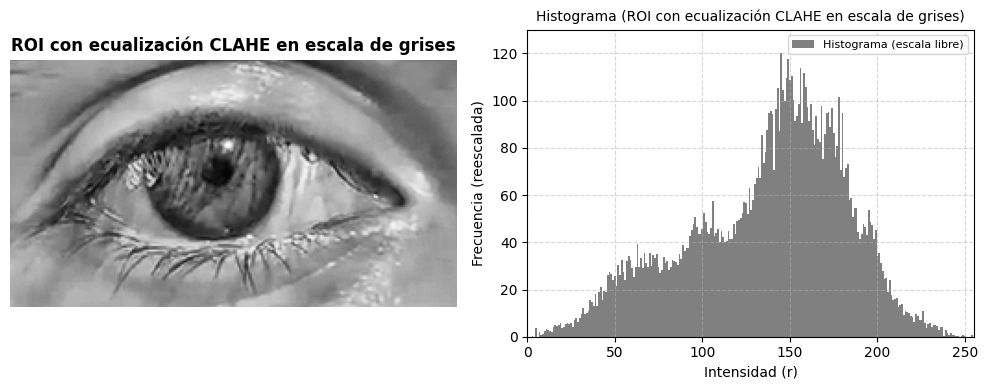

In [4]:
# Aplicar ecualización CLAHE
img_grises_clahe = cf.aplicar_clahe(roi_grises, clahe_clip, clahe_grilla)

# Visualización ROI + HISTOGRAMA
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(10, 4))
img = img_grises_clahe
titulo = "ROI con ecualización CLAHE en escala de grises"

# Imagen ecualizada
axes[0].imshow(img, cmap="gray", vmin=0, vmax=255)
axes[0].set_title(titulo, fontsize=12, fontweight="bold")
axes[0].axis("off")  

# Histograma 
hist_og = cf.histograma(img) if hasattr(cf, 'histograma') else np.bincount(img.ravel(), minlength=256)
hist_og = np.asarray(hist_og, dtype=float)

axes[1].bar(range(256), hist_og / hist_og.max() * 120, width=1, color="gray", edgecolor="none", label="Histograma (escala libre)")
axes[1].set_xlim(0, 255)
axes[1].set_ylim(0, 130)  
axes[1].set_xlabel("Intensidad (r)")
axes[1].set_ylabel("Frecuencia (reescalada)")
axes[1].set_title(f"Histograma ({titulo})", fontsize=10)
axes[1].grid(True, linestyle="--", alpha=0.5)
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

## 3. Estimación del centro y radio de la pupila

Algoritmos de contornos activos como **Snake** requieren la inicialización de una curva cercana al objeto que se desea segmentar. La función `estimar_pupila` resuelve la inicialización de forma automática, calculando el centro $(c_x, c_y)$ y el radio $r$ de la pupila. Aprovecha que tanto el iris como la pupila son *discos oscuros rodeados de algo más claro*. Antes de buscar, suaviza la imagen con un gaussiano de 5×5.

**Mapa de contraste.** Para un radio candidato $r$ se calcula, en cada posición de la imagen, el brillo medio de un *anillo exterior* ($1.15r$ a $1.6r$) menos el brillo medio de un *disco interior* de radio $r$. Un valor alto indica un disco oscuro rodeado de una zona más clara.

La búsqueda se hace en dos etapas:
1. **Iris:** se prueban radios entre el 10 % y el 17 % del ancho de la ROI y se queda con el par (posición, radio) de mayor contraste. Acotar el radio evita que gane una sombra o un grupo de pestañas. Si el contraste máximo es menor a `contraste_min` (25 niveles de gris), se devuelve `None` (por ejemplo, en un parpadeo).
2. **Pupila:** se repite la búsqueda con radios entre el 20 % y el 60 % del radio del iris, pero solo con centros a menos de medio radio de iris del centro del iris. Como se mide el contraste de un disco completo, funciona aunque un reflejo tape parte de la pupila.

Devuelve `(cx, cy, r)` en píxeles de la ROI, o `None`. Al inicializar Snake o los marcadores de Watershed, el resultado se escala con un factor definido en `config.yaml`.


Centro: (112.0, 60.0), Radio: 10.0 px


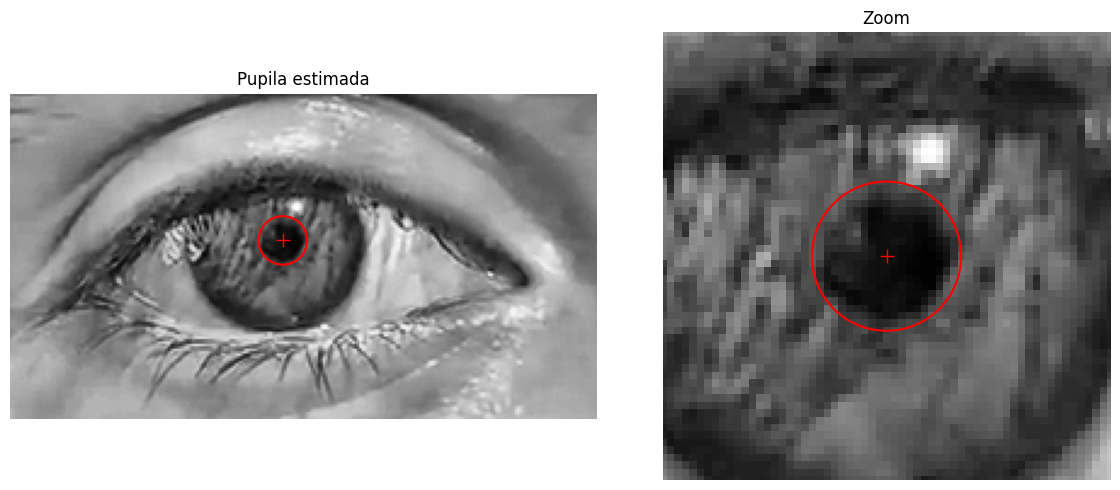

In [5]:
#===========================================================================
# Estimación de las coordenadas del centro y el radio de la pupila para SNAKE y WATERSHED.
#===========================================================================

# Llamada a la función de estimación.
resultado = seg.estimar_pupila(img_grises_clahe) 

if resultado is None:
    print("No se encontró ninguna región candidata.")
else:
    # Extrae coordenadas de centro y radio en píxeles.
    cx, cy, r = resultado 
    print(f"Centro: ({cx:.1f}, {cy:.1f}), Radio: {r:.1f} px")

    # Visualización de la estimación
    fig, ax = plt.subplots(1, 2, figsize=(12, 5))

    # Imagen completa con la pupila estimada.
    ax[0].imshow(img_grises_clahe, cmap="gray")
    ax[0].add_patch(plt.Circle((cx, cy), r, fill=False, color="r", linewidth=1.5))
    ax[0].plot(cx, cy, "r+", markersize=10)
    ax[0].set_title("Pupila estimada")

    # Zoom alrededor de la pupila, para ver si calza.
    margen = int(3 * r)
    ax[1].imshow(img_grises_clahe, cmap="gray")
    ax[1].add_patch(plt.Circle((cx, cy), r, fill=False, color="r", linewidth=1.5))
    ax[1].plot(cx, cy, "r+", markersize=10)
    ax[1].set_xlim(cx - margen, cx + margen)
    ax[1].set_ylim(cy + margen, cy - margen)   # eje y invertido: las filas crecen hacia abajo
    ax[1].set_title("Zoom")

    for a in ax:
        a.axis("off")
    plt.tight_layout()
    # Guardo resultado.
    fig.savefig(raiz / "results" / "modulo2" / "2_1_3_estimacion_pupila.png", dpi=150, bbox_inches="tight")
    plt.show()


## 4. Segmentación por umbralización automática (Otsu)

El método de **Otsu** es un algoritmo de umbralizado automático basado en la estadística global del histograma. Asume que la imagen se compone de dos poblaciones separadas por un umbral $T$ en el nivel de gris k. Este umbral es el óptimo, pues consigue la mayor variabilidad interclase 
(entre las dos poblaciones) y la menor variabilidad intraclase (dentro de una misma población).

Otsu segmenta bien cuando el histograma de la imagen es bimodal, es decir, presenta dos modas bien marcadas. Sin embargo, se observó en el módulo 1 que este no es el caso para el frame analizado, por lo cual se espera un resultado deficiente.

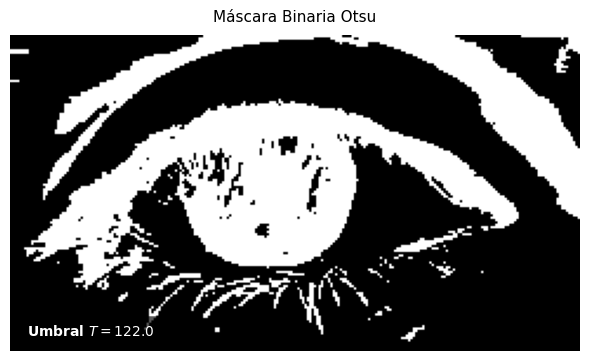

In [6]:
#===========================================================================
# Segmentación con OTSU
#===========================================================================
# Devuelve la máscara binaria y el valor del umbral T calculado.
umbral_otsu, mascara_otsu = seg.segmentar_otsu(img_grises_clahe)

# Guardo la máscara binaria en resultados, para después usarla en el módulo 4.
cv2.imwrite(str(raiz / "results" / "modulo2" / "2_1_4_otsu_mascara.png"), mascara_otsu)

# Gráfico
fig, ax = plt.subplots(figsize=(6, 5))
ax.imshow(mascara_otsu, cmap="gray")

ax.set_title("Máscara Binaria Otsu", fontsize=11, pad=10)

texto_umbral = f"Umbral $T = {umbral_otsu}$"
ax.text(
    0.03, 0.05, texto_umbral,                   
    transform=ax.transAxes,
    fontsize=10,
    fontweight="bold",
    color="white",
    bbox=dict(boxstyle="round,pad=0.5", facecolor="black", alpha=0.65, edgecolor="none") # Cuadro semi-transparente
)

ax.axis("off")
plt.tight_layout()

# Guardo en resultados.
fig.savefig(raiz / "results" / "modulo2" / "2_1_4_otsu.png", dpi=150, bbox_inches="tight")
plt.show()

### Resultado de Otsu

Otsu calcula un único umbral global (T = 123) sobre toda la ROI, y la máscara resultante **no aísla la pupila**, sino que cubre prácticamente 1/3 de la misma.

La causa es que la pupila es un % bajo de los píxeles y el histograma está dominado por la piel y el iris: Otsu separa "oscuro" de "claro", por lo que también captura pestañas, sombras y zonas oscuras del iris. 

Concluimos que una umbralización global no alcanza para este problema. Para usarlo habría que restringirlo a una ventana alrededor de la pupila estimada o emplear un umbral local.

## 5. Segmentación por contornos activos Snake

Los **contornos activos (Snake)** son curvas parametrizadas que evolucionan sobre la imagen minimizando una función de energía interna (suavidad y continuidad de la curva) y externa (gradientes de intensidad de la imagen). El contorno activo se modela como un sistema físico en el que hay fuerzas internas y externas actuando sobre él.

### Estrategia de Inicialización:
1. Tomamos las coordenadas $(c_x, c_y)$ y el radio $r$ estimados previamente con `estimar_pupila`.
2. Multiplicamos el radio inicial por un factor (ej. $1.15 \times r$) para garantizar que la curva inicial rodee completamente la pupila y colapse hacia sus bordes reales.
3. Parámetros del planteo energético:
   * $\alpha$ (*alpha*): controla la elasticidad/tensión, qué tan fuerte se contrae la curva. Mide cómo avanza cada puntito individual con libertad en dirección perpendicular hacia el borde que intenta alcanzar. Para este frame, se ha seleccionado $\alpha = 0.015$.
   * $\beta$ (*beta*): controla la rigidez, la resistencia de la curva al doblarse. Mide el movimiento de varios puntos de la curva en conjunto. Se ha seleccionado $\beta = 10$.
   * $\gamma$ (*gamma*): paso de adaptación/velocidad de convergencia. Se utiliza en este caso  $\gamma = 0.01$.
  
Los parámetros $\alpha$, $\beta$ y $\gamma$ se ajustaron de forma empírica, probando distintos valores y observando el resultado sobre el frame de trabajo.
  
### Decisiones de implementación

* **Curva inicial:** un círculo de 100 puntos equiespaciados en ángulo, centrado en $(c_x, c_y)$. `active_contour` trabaja con coordenadas (fila, columna), por eso el seno va en la primera coordenada.
* **Suavizado previo:** la imagen se filtra con un gaussiano ($k = 15$, $\sigma = 3$) y se normaliza al rango $[0, 1]$, que es lo que espera `active_contour`. El suavizado evita que la curva se enganche en pestañas, en el reflejo o en la textura del iris.
* **Energía externa:** se usa `w_line = 0` y `w_edge = 1`. La curva se atrae solo hacia bordes (gradiente) y no hacia un nivel de brillo, de modo que no depende de la iluminación del frame.
* **Límite de iteraciones:** se fijan 500 iteraciones máximas para garantizar que el algoritmo termine (esto es FUNDAMENTAL).
* **Conversión a máscara:** el contorno final se rellena como polígono, por lo que la máscara siempre es una única región cerrada.
* **Dependencia de la estimación:** el resultado depende de `estimar_pupila`; si no encuentra la pupila (`None`), el Snake no puede ejecutarse.

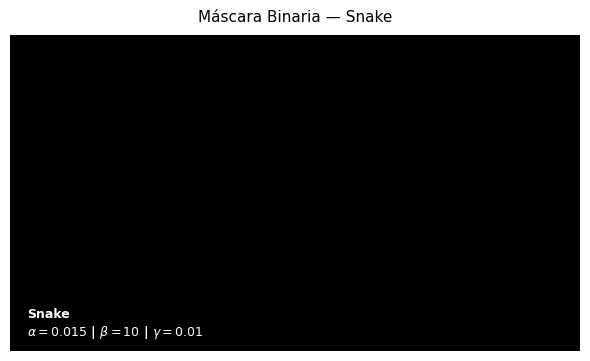

In [7]:
#===========================================================================
# Segmentación con SNAKE
#===========================================================================
cx, cy, r = seg.estimar_pupila(img_grises_clahe)


# Llamado a la función correspondiente.
# Nótese que 'factor_radio_inicial;, 'k', 'sigma', 'alpha','beta' y 'gamma' fueron
# definidos previamente, pues son parámetros guardados en ´config.yaml´

mascara_snake, contorno = seg.segmentar_snake(
    img_grises_clahe, cx, cy, r,
    factor_radio_inicial, k, sigma,alpha, beta, gamma)

# Guardo la máscara binaria en resultados, para después usarla en el módulo 4.
cv2.imwrite(str(raiz / "results" / "modulo2" / "2_1_5_Snake_mascara.png"), mascara_snake)


# Visualización
fig, ax = plt.subplots(figsize=(6, 5))

ax.imshow(mascara_snake, cmap="gray")
ax.set_title("Máscara Binaria — Snake", fontsize=11, pad=10)

texto_snake = f"Snake\n$\\alpha={alpha}$ | $\\beta={beta}$ | $\\gamma={gamma}$"
ax.text(
    0.03, 0.05, texto_snake,
    transform=ax.transAxes,
    fontsize=9,
    fontweight="bold",
    color="white",
    bbox=dict(boxstyle="round,pad=0.5", facecolor="black", alpha=0.65, edgecolor="none")
)

ax.axis("off")

# Guardo figura en resultados\modulo2
fig.savefig(raiz / "results" / "modulo2" / "2_1_5_Snake.png", dpi=150, bbox_inches="tight")

plt.tight_layout()
plt.show()

### Resultado de Snake

La curva converge a una única región cerrada y suave, pero no conserva la forma circular de la inicialización: adquiere una forma de gota, con la punta orientada hacia el reflejo corneal, probablemente atraída por su fuerte gradiente. Su área (a ojo) es menor que la del círculo inicial. Además, es sensible a sus parámetros: fuera de cierto rango el contorno colapsa.

## 7. Segmentación por Watershed

Este método interpreta a una imagen en escala de grises como un mapa topográfico en 3D, donde la base (x,y) son las coordenadas espaciales de los píxeles, y la altura z es el nivel de gris. De esta forma, se define:
 * Los píxeles de baja intensidad actúan como valles, cuencas.
 * Los píxeles claros actúan como crestas de montañas.

El algoritmo simula la inundación de cada cuenca (mínimos locales de intensidad) hasta que el agua de dos cuencas distintas se encuentran. En ese punto, se levanta un *dique* en la línea divisoria de agua. 

Al finalizar el llenado, los diques construidos constituyen fronteras, dividiendo la imagen en regiones independientes.

El problema de este método reside en la sensibilidad al ruido y consecuente sobresegmentación. Para evitar esto, se aplica Watershed controlado por marcadores: el usuario o un algoritmo previo define explícitamente semillas internas y externas.
1. **Marcador interno (pupila):** un círculo de radio $0.5\,r$ centrado en $(c_x, c_y)$, que cae seguro dentro de la pupila.
2. **Marcador externo (fondo):** un anillo entre $1.3\,r$ y $1.8\,r$ alrededor del centro. Empieza fuera de la pupila y alcanza con que el "agua" del fondo llegue a la cresta que rodea la pupila.

Estos marcadores se calculan por medio de la función `crear_marcadores`.

El algoritmo de Watershed se aplicó no sobre la imagen en escala de grises en este caso, sino sobre un *mapa de la magnitud del gradiente* generado por un 
**filtro Sobel**.
Así, las regiones homogéneas interiores se convierten en valles y los bordes de los objetos se transforman en crestas de montaña, obteniéndose una estructura topográfica ideal para trazar las líneas divisorias.



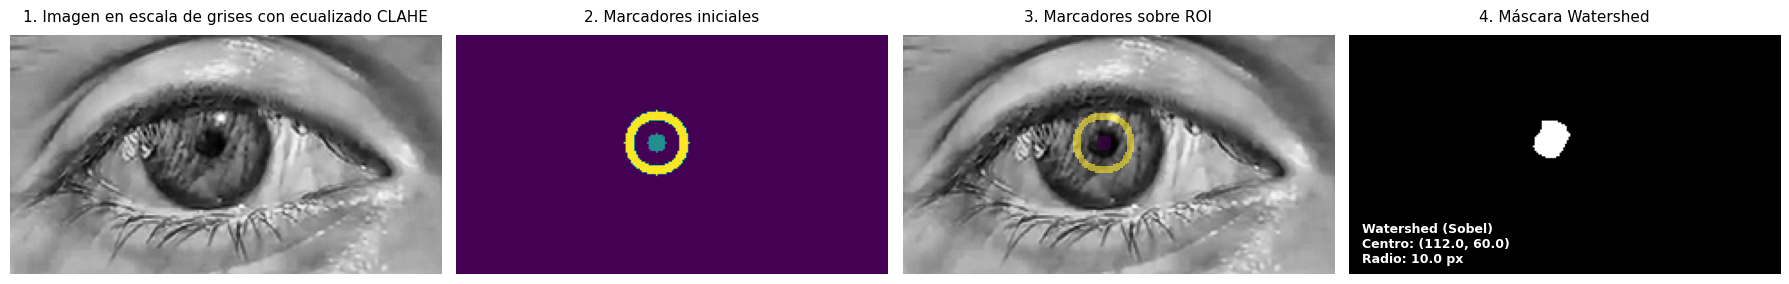

In [8]:
# ===========================================================================
# Segmentación con Watershed por Marcadores
# ===========================================================================

# Estimación e inicialización de marcadores
estimacion = seg.estimar_pupila(img_grises_clahe)

if estimacion is None:
    print("No se pudo estimar la pupila en esta imagen.")
else:
    cx, cy, r = estimacion

    # Crear marcadores y segmentar sobre el gradiente Sobel
    # Los parámetros factor_interior, factor_anillo_interior y factor_anillo_exterior están definidos en ´config.yaml´.
    marcadores = seg.crear_marcadores(img_grises_clahe, cx, cy, r,factor_interior, factor_anillo_interior, factor_anillo_exterior)
    mascara_watershed, etiquetas_watershed = seg.segmentar_watershed(img_grises_clahe, marcadores)

    # 1) Máscara binaria sola a carpeta Resultados (bool -> uint8 con 0 / 255)
    cv2.imwrite(str(carpeta_res / "2_1_6_watershed.png"),
                mascara_watershed.astype(np.uint8) * 255)
  
    # Visualización 
    fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))

    # Entrada (ROI CLAHE)
    axes[0].imshow(img_grises_clahe, cmap="gray")
    axes[0].set_title("1. Imagen en escala de grises con ecualizado CLAHE", fontsize=11, pad=10)

    # Marcadores
    axes[1].imshow(marcadores, cmap="viridis", vmin=0, vmax=2)
    axes[1].set_title("2. Marcadores iniciales", fontsize=11, pad=10)

    # Marcadores superpuestos sobre la ROI
    axes[2].imshow(img_grises_clahe, cmap="gray")
    axes[2].imshow(
        np.ma.masked_where(marcadores == 0, marcadores),
        cmap="viridis",
        vmin=1,
        vmax=2,
        alpha=0.6
    )
    axes[2].set_title("3. Marcadores sobre ROI", fontsize=11, pad=10)

    # Máscara binaria
    axes[3].imshow(mascara_watershed, cmap="gray")
    axes[3].set_title("4. Máscara Watershed", fontsize=11, pad=10)
    texto_ws = f"Watershed (Sobel)\nCentro: ({cx:.1f}, {cy:.1f})\nRadio: {r:.1f} px"
    axes[3].text(
        0.03, 0.05, texto_ws,
        transform=axes[3].transAxes,
        fontsize=9,
        fontweight="bold",
        color="white",
        bbox=dict(boxstyle="round,pad=0.5", facecolor="black", alpha=0.65, edgecolor="none")
    )

   
    for ax in axes:
        ax.axis("off")

    # Guardo figura en resultados\modulo2
    fig.savefig(raiz / "results" / "modulo2" / "2_1_6_watershed_marcadores.png", dpi=150, bbox_inches="tight")
    plt.tight_layout()
    plt.show()

### Resultado de Watershed

Los marcadores quedan bien ubicados: la semilla interior cae dentro de la pupila y el anillo exterior la rodea sin invadirla. La máscara resultante es una única región compacta que sigue razonablemente el contorno de la pupila, con un pequeño saliente en la parte superior que luego puede corregirse con morfología. El método depende de la estimación previa de centro y radio, ya que de ellas depende la posición de las semillas.

## 8. Agrupar por K - Means (ROI a color)

Se aplicó K-means sobre las características saturación (S) e intensidad (V) del espacio HSV, con K entre 2 y 5. Una primera prueba sobre la ROI completa no permitió aislar la pupila: al ocupar menos del 1 % de los píxeles, el algoritmo, que reparte los grupos según dónde se concentran los datos, los destina a las zonas abundantes (piel, pestañas, iris) y la pupila queda mezclada con alguna de ellas. Por este motivo el método se aplicó sobre una ventana local de tamaño proporcional al radio (3·r) alrededor de la pupila estimada con `estimar_pupila`, donde la pupila deja de ser una fracción despreciable de los datos. Dentro de esa ventana, el grupo correspondiente a la pupila se eligió como el que predomina en el círculo central de radio r.

Los resultados dependen claramente de K. Con K=2 y K=3 hay pocos grupos para separar tantas zonas, por lo que el grupo más oscuro absorbe también sombras y regiones marrones del iris, y el contorno se extiende más allá de la pupila. Con K=4 y K=5 el contorno se ajusta mejor al núcleo oscuro, porque hay grupos suficientes para separar la pupila del iris. La diferencia entre ambas áreas es pequeña, lo que sugiere que a partir de K=4 el resultado se estabiliza.

Aun con K=4 y K=5, la máscara tiene dos limitaciones. Por un lado, captura la parte más oscura de la pupila pero deja afuera una zona azulada de su borde, que en el espacio S–V queda más cerca de otro grupo que del negro puro; por eso el área tiende a subestimar la pupila real. Por otro, al clasificar píxeles por color sin considerar su posición, aparecen regiones pequeñas aisladas (pestañas, sombras, reflejo corneal) que comparten el grupo de la pupila.

En conjunto, K-means resulta sensible a la elección de K y no incorpora información espacial, y además depende de una estimación previa de la posición de la pupila para funcionar. Estas características lo hacen menos robusto que Watershed para aplicarlo a todos los cuadros del video, aunque sirve como comparación de un enfoque basado en color. 

c:\Users\ronal\AppData\Local\Programs\Python\Python312\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\ronal\AppData\Local\Programs\Python\Python312\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Users\ronal\AppData\Local\Programs\Python\Python312\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\ronal\AppData\Local\Programs\Python\Python312\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  

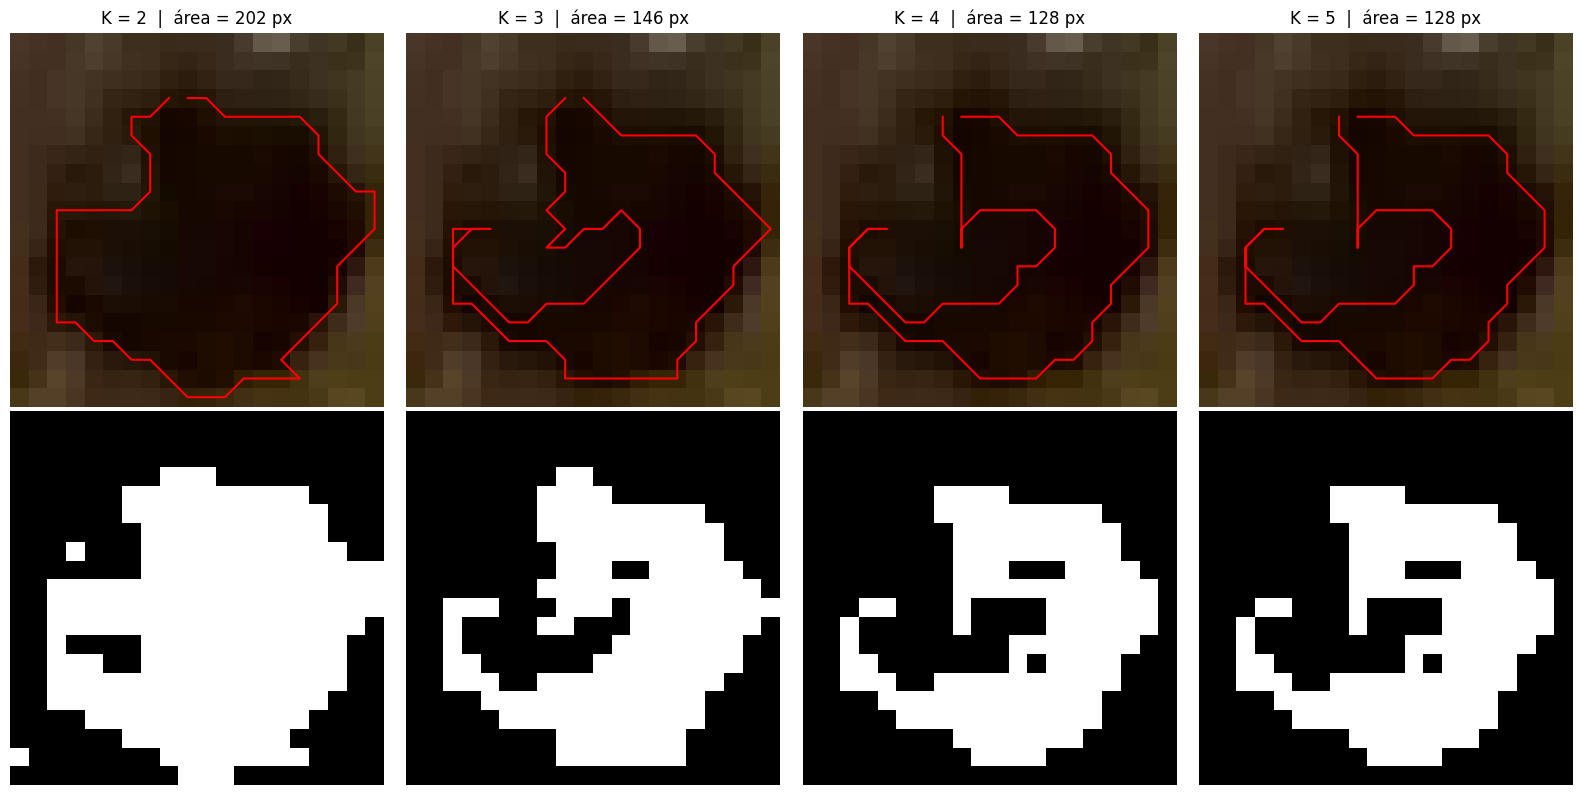

In [9]:
cx, cy, r = seg.estimar_pupila(img_grises_clahe)

def mostrar_kmeans(roi, cx, cy, r, ks=(2, 3, 4, 5), factor_ventana=3, zoom=True):
    """
    Corre segmentar_kmeans para cada K y grafica, por columna:
      - arriba: el contorno de la máscara sobre la ROI a color
      - abajo: la máscara binaria (blanco = pupila)
    Devuelve un dict {K: máscara}.
    """
    mascaras = {}
    for k in ks:
        mascaras[k] = seg.segmentar_kmeans(roi, cx, cy, r, k=k, factor_ventana=factor_ventana)

    # recorte para ver la pupila más de cerca (solo para graficar)
    alto, ancho = roi.shape[:2]
    mitad = int(factor_ventana * r)
    if zoom:
        x0, x1 = max(int(cx) - mitad, 0), min(int(cx) + mitad, ancho)
        y0, y1 = max(int(cy) - mitad, 0), min(int(cy) + mitad, alto)
    else:
        x0, x1, y0, y1 = 0, ancho, 0, alto

    n = len(ks)
    fig, ejes = plt.subplots(2, n, figsize=(4 * n, 8), squeeze=False)

    for j, (k, mascara) in enumerate(mascaras.items()):
        recorte = mascara[y0:y1, x0:x1]
        area = int((mascara > 0).sum())

        # fila de arriba: contorno rojo sobre la ROI
        eje = ejes[0, j]
        eje.imshow(roi[y0:y1, x0:x1])
        contornos, _ = cv2.findContours(recorte, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        for c in contornos:
            eje.plot(c[:, 0, 0], c[:, 0, 1], "r", linewidth=1.5)
        eje.set_title(f"K = {k}  |  área = {area} px")
        eje.axis("off")

        # fila de abajo: máscara binaria
        eje = ejes[1, j]
        eje.imshow(recorte > 0, cmap="gray", vmin=0, vmax=1)
        eje.axis("off")

    fig.tight_layout()

    # Guardar imagen en resultados
    
    fig.savefig(carpeta_res / "2_1_7_k_means.png", dpi=150, bbox_inches="tight")

    plt.show()
    return mascaras


mascaras_kmeans = mostrar_kmeans(roi, cx, cy, r, ks=(2, 3, 4, 5), factor_ventana=factor_ventana)
mascara_kmeans_5 = mascaras_kmeans[5]   # máscara con K=5

### Resultados: K-means en el espacio croma/intensidad

Los resultados dependen claramente de K. El área de la máscara disminuye de forma sostenida al aumentar K (236, 178, 144 y 114 px para K=2, 3, 4 y 5). Con pocos grupos, el grupo más oscuro absorbe además sombras de pestañas y párpado, por lo que la máscara se extiende más allá de la pupila y aparecen regiones grandes y píxeles dispersos. Al aumentar K esas zonas se separan y la máscara se vuelve más compacta, a costa de reducir también la porción de pupila capturada. En este frame, K=5 produce la máscara visualmente más limpia-

En ningún valor de K la máscara cubre la pupila completa: se obtiene una región en forma de media luna que corresponde a su parte más oscura. Una explicación probable es que la pupila no tiene un valor uniforme en la imagen, debido a la iluminación lateral, que hace que su mitad izquierda sea más clara. Como K-means agrupa únicamente por valores de S y V, sin considerar la forma ni la posición, los píxeles de esa zona quedan más cerca del grupo del iris que del grupo de la pupila y se excluyen. 

Además, las máscaras binarias presentan huecos y píxeles aislados, ya que el método clasifica cada píxel de forma independiente. 

En conjunto, K-means resulta sensible a la elección de K y a la iluminación no uniforme, no incorpora información espacial y requiere una estimación previa de la posición de la pupila. 

## 8. Comparación de los cuatro métodos

Se muestran las máscaras obtenidas con Otsu, Snake, Watershed y K-means (K=5) sobre la misma ROI en escala de grises con CLAHE, primero como contorno superpuesto a la imagen (para verificar si calza con la pupila) y luego como máscaras binarias (blanco = pupila).

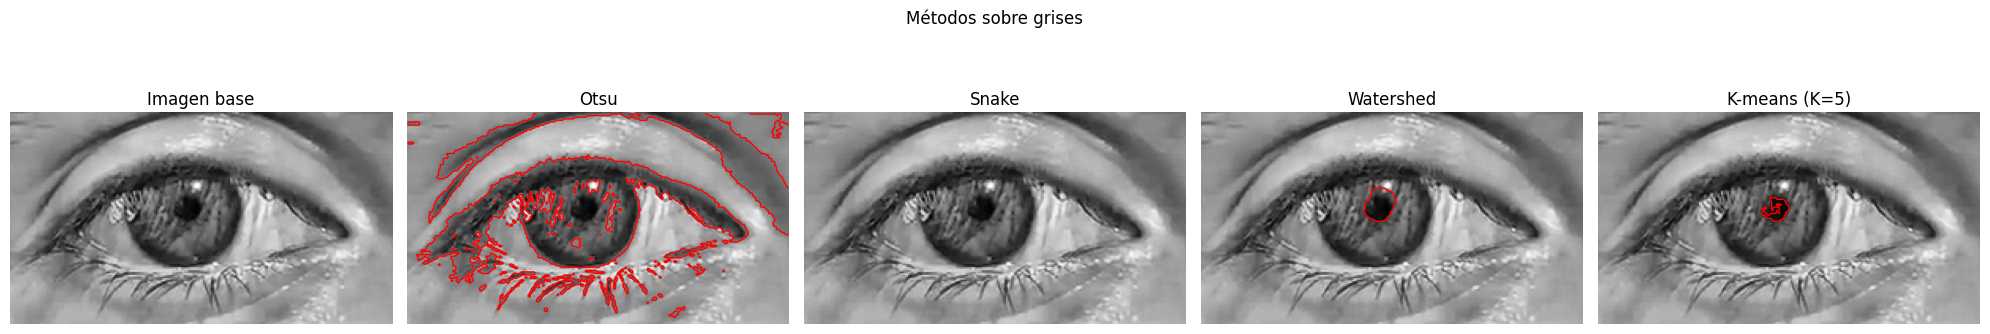

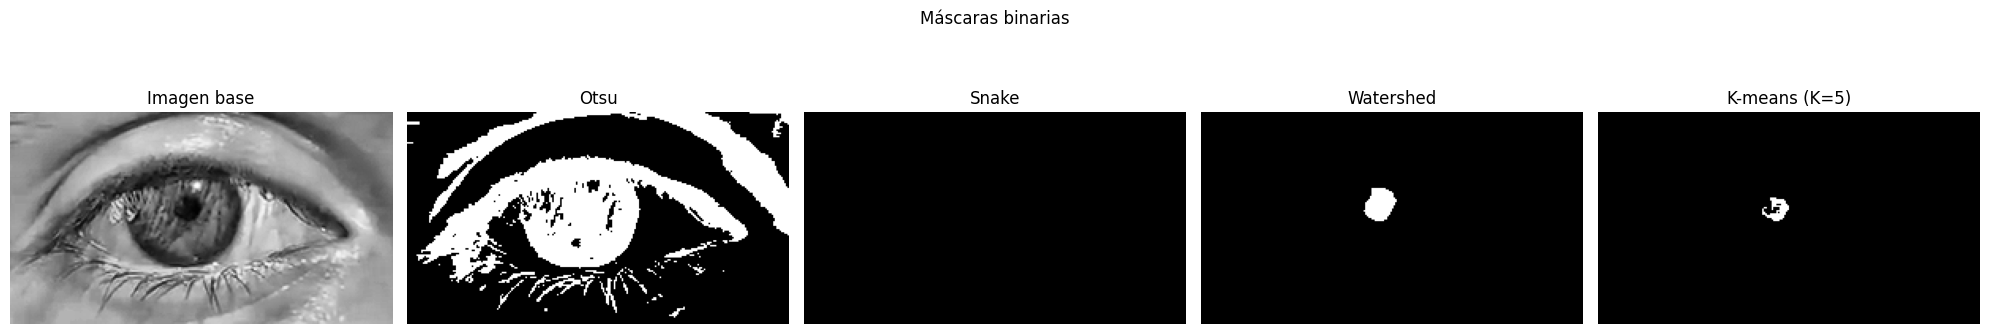

In [10]:

def mostrar_mascaras_sobre_grises(base, mascaras, titulo, guardar_como=None, carpeta=None, cmap_base="gray"):
    """Muestra la imagen base y, al lado, cada máscara con su contorno
    superpuesto sobre la base, para poder verificar si calza con la pupila."""
    n = len(mascaras) + 1
    fig, ax = plt.subplots(1, n, figsize=(4 * n, 4))

    ax[0].imshow(base, cmap=cmap_base)
    ax[0].set_title("Imagen base")

    for i, (nombre, m) in enumerate(mascaras.items(), start=1):
        ax[i].imshow(base, cmap=cmap_base)
        ax[i].contour(m > 0, levels=[0.5], colors="r", linewidths=1)
        ax[i].set_title(nombre)

    for a in ax:
        a.axis("off")
    fig.suptitle(titulo)

    # Guardo imagen en resultados.
    if guardar_como is not None:
            carpeta = carpeta if carpeta is not None else carpeta_res
            carpeta.mkdir(parents=True, exist_ok=True)
            fig.savefig(carpeta / guardar_como, dpi=150, bbox_inches="tight")

    plt.tight_layout()
    plt.show()


def mostrar_mascaras_binarias(base, mascaras, titulo, guardar_como=None, carpeta=None):
    """Muestra la imagen base y las máscaras binarias de cada método."""

    n = len(mascaras) + 1
    fig, ax = plt.subplots(1, n, figsize=(4 * n, 4))

    # Imagen base
    ax[0].imshow(base, cmap="gray")
    ax[0].set_title("Imagen base")

    # Máscaras binarias
    for i, (nombre, m) in enumerate(mascaras.items(), start=1):
        ax[i].imshow(m > 0, cmap="gray", vmin=0, vmax=1)
        ax[i].set_title(nombre)

    for a in ax:
        a.axis("off")

    fig.suptitle(titulo)

    if guardar_como is not None:
        carpeta = carpeta if carpeta is not None else carpeta_res
        carpeta.mkdir(parents=True, exist_ok=True)
        fig.savefig(carpeta / guardar_como, dpi=150, bbox_inches="tight")

    
    plt.tight_layout()
    plt.show()

mascaras = {
    "Otsu": mascara_otsu,
    "Snake": mascara_snake,
    "Watershed": mascara_watershed,
    "K-means (K=5)": mascara_kmeans_5,
}

mostrar_mascaras_sobre_grises(img_grises_clahe, mascaras, "Métodos sobre grises", guardar_como="2_1_8_comparativa_sobre_grises")
mostrar_mascaras_binarias(img_grises_clahe, mascaras, "Máscaras binarias", guardar_como="2_1_8_comparativa_mascaras_binarias")



### Análisis comparativo de los métodos de segmentación

Los cuatro métodos se aplicaron sobre la misma ROI del mismo frame, en escala de grises con CLAHE (en el caso de K-means, sobre los canales S y V de la ROI a color). Otsu y K-means clasifican cada píxel según su valor (intensidad o color) sin considerar su posición, mientras que Snake y Watershed trabajan con el gradiente de la imagen (la energía externa en Snake y el relieve en Watershed) y parten de una estimación previa del centro y el radio de la pupila. Las áreas se expresan en píxeles; para convertirlas a unidades físicas es necesario definir la relación entre píxeles y distancia real.

**Otsu.** La máscara incluye el iris, los párpados y las pestañas, por lo que no aísla la pupila. El resultado es coherente con el fundamento del método: Otsu calcula un único umbral que maximiza la varianza entre dos clases y solo da buenos resultados cuando el histograma es bimodal. En una imagen de ojo coexisten más de dos poblaciones de intensidad (pupila, iris, esclerótica, piel y pestañas) y, como el histograma no conserva información espacial, el umbral no distingue la pupila de otras zonas igualmente oscuras. Su máscara no es utilizable para medir la pupila.

**K-means.** Se aplicó en el espacio saturación–intensidad (S, V) con K entre 2 y 5, sobre una ventana local de tamaño 3·r alrededor de la pupila estimada, y el grupo de la pupila se eligió como el predominante dentro del círculo central de radio r. Se usó una ventana local porque en la ROI completa la pupila ocupa una fracción mínima de los píxeles y los grupos se reparten entre las zonas más abundantes. El área de la máscara disminuye al aumentar K (236, 178, 144 y 114 px para K=2, 3, 4 y 5), en coincidencia con que a mayor K cada grupo contiene menos píxeles y el agrupamiento es más detallado: con pocos grupos, el más oscuro incorpora otras zonas oscuras de la ventana, y al aumentar K esas zonas se separan y la máscara se vuelve más compacta, aunque también más pequeña. En este frame K=5 produce la máscara visualmente más limpia, pero la elección del mejor K requiere la comparación cuantitativa. En ningún caso la máscara cubre toda la pupila: queda una región en forma de medialuna correspondiente a su parte más oscura. Una explicación posible es que la iluminación no sea uniforme sobre la pupila, de modo que un sector es más claro que otro; como K-means usa un único criterio de color sin considerar la forma, ese sector se asigna a otro grupo. Además, al clasificar cada píxel de forma independiente, la máscara presenta huecos y píxeles aislados, que son el tipo de imperfección que corrigen la apertura y el cierre morfológicos, y que podría agravarse por no haber suavizado la imagen antes de agrupar.

**Snake.** Se inicializó un contorno circular de radio 1,15·r alrededor de la pupila estimada, y la imagen se suavizó con un filtro gaussiano antes de calcular la energía externa. Snake devuelve únicamente las coordenadas del contorno; la máscara se obtuvo rellenando el polígono delimitado por esos puntos. El contorno resulta suave y compacto, y queda por dentro de la pupila y algo desplazado, con un área menor que la real. Es consistente con las limitaciones del método: depende de una buena inicialización, puede quedar atrapado en mínimos locales y necesita bordes bien definidos; además, con una rigidez β alta (β = 10, valor utilizado) el contorno es rígido y redondeado, y con una tensión α baja (α = 0,015) cada punto se mueve con mayor libertad. En frames oscuros o de bajo contraste el borde entre pupila e iris es débil y la atracción del gradiente disminuye. Una alternativa para bordes débiles es Chan-Vese, que se basa en la homogeneidad de intensidad dentro y fuera del contorno y no en el gradiente, aunque no fue evaluada.

**Watershed.** Se aplicó Watershed controlado por marcadores sobre la magnitud del gradiente de Sobel, tomando el gradiente como relieve (los bordes son las crestas). Los marcadores se definen a partir de la estimación previa de la pupila: un disco interior de radio 0,5·r se etiqueta como pupila, un anillo entre 1,3·r y 1,8·r se asume como fondo, y la zona intermedia queda sin etiquetar; la inundación avanza desde ambos marcadores y el dique se construye sobre el borde más marcado entre ellos. No se aplicó suavizado previo: el ruido se controla mediante los marcadores, que impiden que cada mínimo local genere su propia cuenca. Es el método que produce la región más regular y centrada. Su limitación es que el resultado queda acotado por los marcadores, ya que la máscara no puede extenderse más allá de 1,3·r ni contraerse por debajo de 0,5·r, por lo que depende de que el radio estimado sea razonablemente cercano al real.

**Dependencia de la estimación inicial.** Snake, Watershed y K-means parten de la misma estimación del centro y el radio, por lo que un error en esa etapa los afecta a los tres. Otsu es el único método independiente de esa estimación, pero también el único que no logra siquiera aproximarse a la máscara de la pupila.

**Limitaciones.** El pipeline aplica solo CLAHE antes de segmentar, sin un filtrado global de ruido; el suavizado se incorpora únicamente dentro de Snake, y Otsu y K-means trabajan sin él. Las diferencias de calidad observadas no permiten por sí solas determinar qué método reproduce mejor la pupila real.


## 9. Prueba sobre distintos frames del video
Se toman distintos frames del video para evaluar cómo se ajusta cada método a los mismos.

True


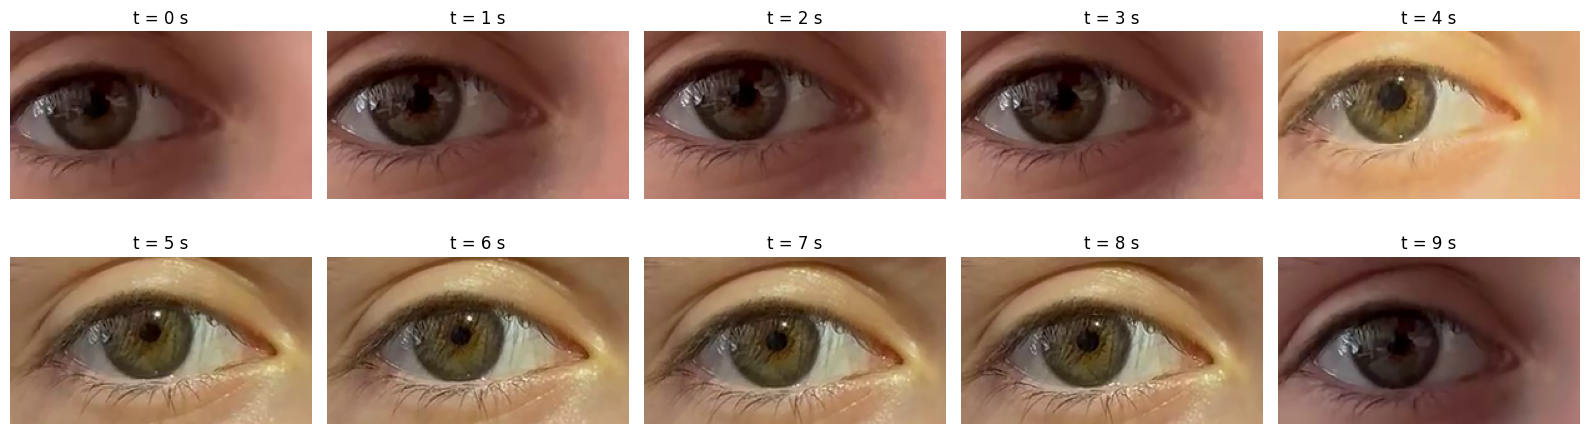

In [11]:
ruta_video = raiz / cfg["entrada"]["video_path"]
print(ruta_video.exists())      # tiene que devolver True; si da False, el video no está en el repo.

tiempos = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]    

fig, ejes = plt.subplots(2, 5, figsize=(16, 5))
for eje, t in zip(ejes.ravel(), tiempos):
    frame = cm.extraer_frame(ruta_video, t)
    eje.imshow(cm.recortar_roi(frame, cfg["roi"]))
    eje.set_title(f"t = {t} s")
    eje.axis("off")
plt.tight_layout()
plt.show()

In [12]:
def procesar_frame(t, cfg, raiz):
    """Frame en t segundos -> ROI -> grises + CLAHE -> pupila -> 4 métodos.
    Devuelve un dict con todo; no grafica nada."""

    # 1. Frame y ROI
    frame = cm.extraer_frame(raiz / cfg["entrada"]["video_path"], t)
    roi = cm.recortar_roi(frame, cfg["roi"])

    # 2. Grises + CLAHE
    img_clahe = cf.aplicar_clahe(cf.conv_grises(roi),clahe_clip,clahe_grilla) 

    # 3. Estimar la pupila (puede devolver None, por ejemplo en un parpadeo)
    pupila = seg.estimar_pupila(img_clahe)
    if pupila is None:
        return {"roi": roi, "gris": img_clahe, "pupila": None, "mascaras": {}}
    cx, cy, r = pupila

    # 4. Los cuatro métodos
    mascaras = {}
    _, mascaras["Otsu"] = seg.segmentar_otsu(img_clahe)

    mascaras["Snake"], _ = seg.segmentar_snake(
        img_clahe, cx, cy, r,
        factor_radio_inicial, k, sigma, alpha, beta, gamma)

    marcadores = seg.crear_marcadores(img_clahe, cx, cy, r,factor_interior, factor_anillo_interior, factor_anillo_exterior)
    mascaras["Watershed"] , etiquetas= seg.segmentar_watershed(
        img_clahe, marcadores)   

    mascaras[f"K-means (K=5)"] = seg.segmentar_kmeans(
        roi, cx, cy, r, k=5, factor_ventana=factor_ventana)

    return {"roi": roi, "gris": img_clahe, "pupila": (cx, cy, r), "mascaras": mascaras}


Se toman tiempos equiespaciados para hacer la prueba de los métodos sobre sus frames.

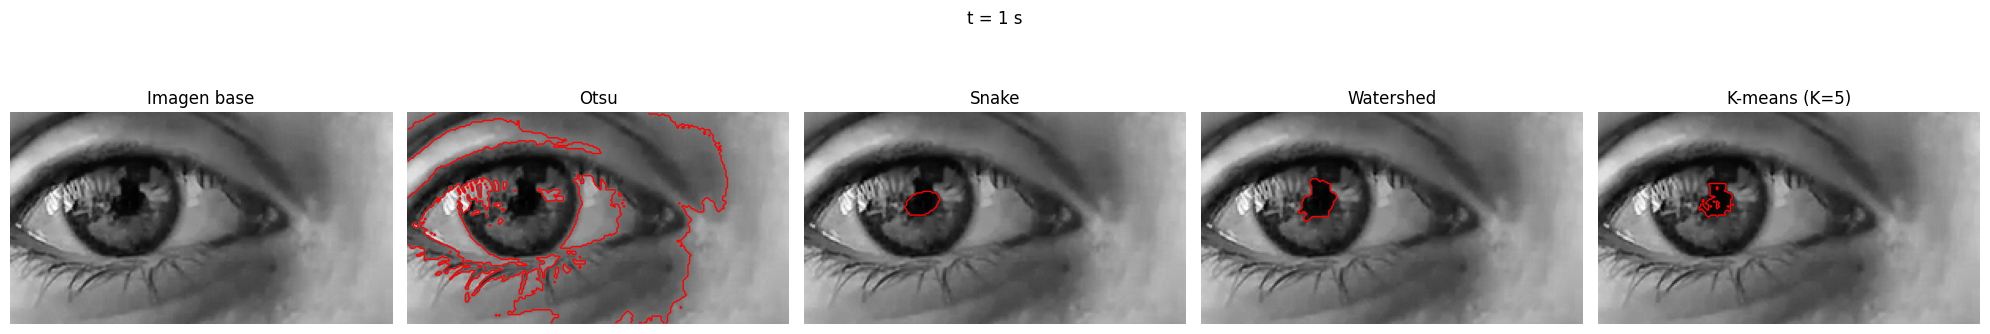

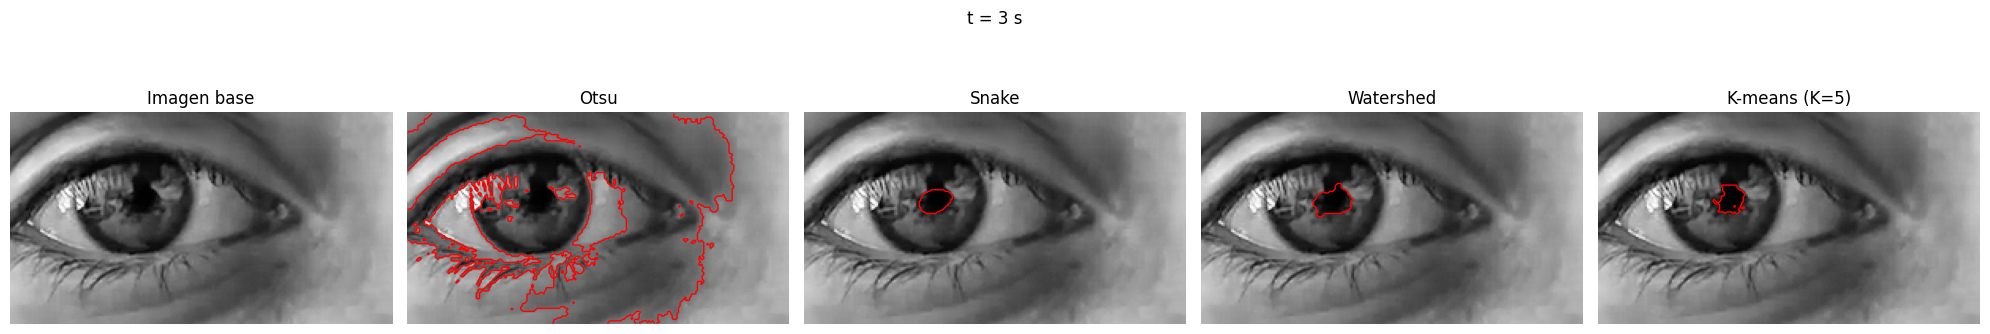

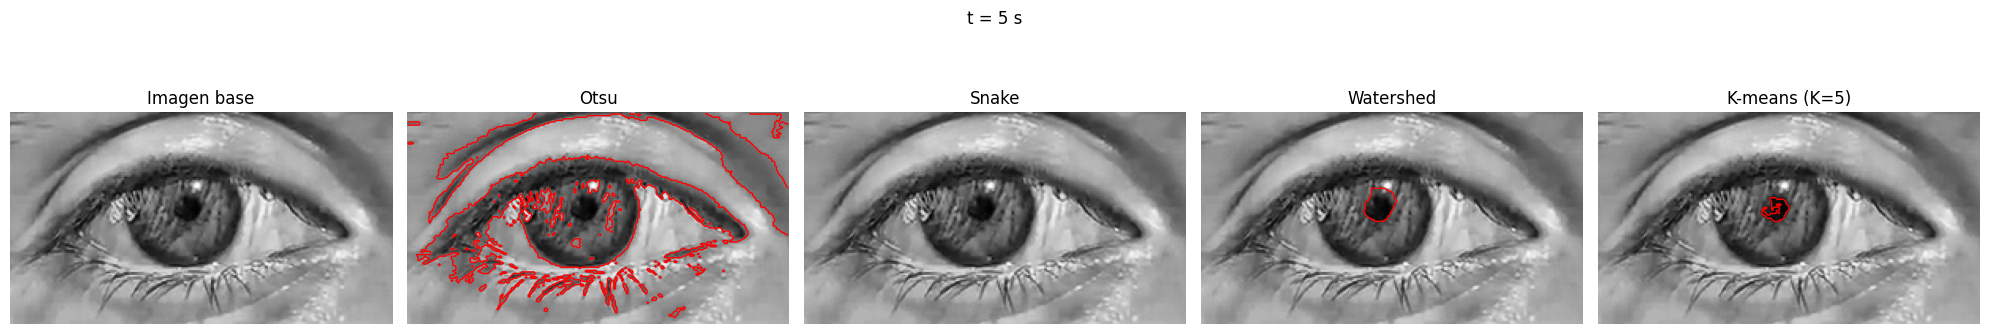

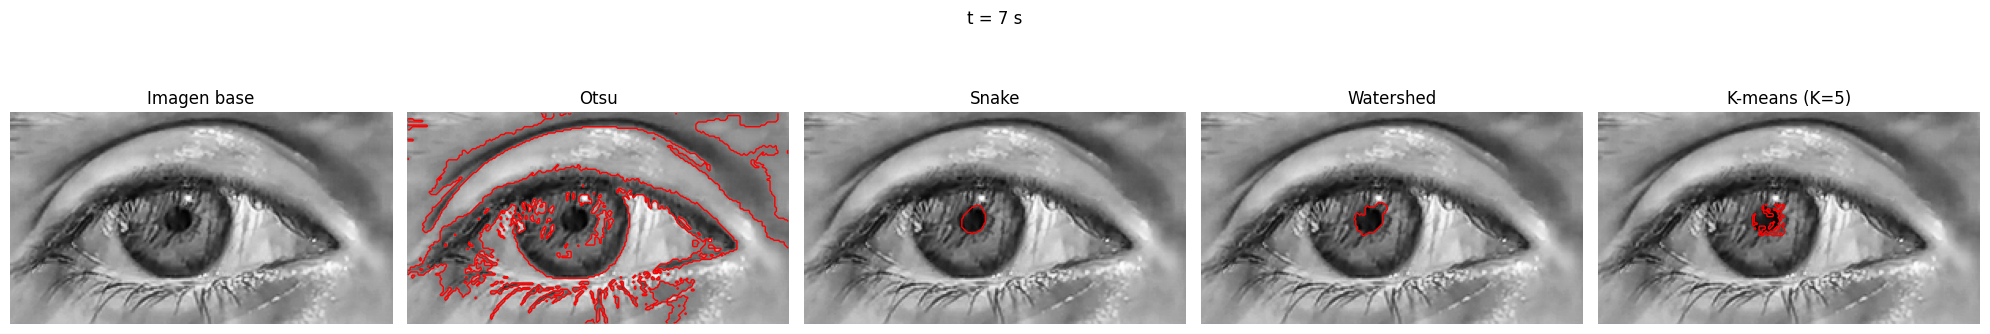

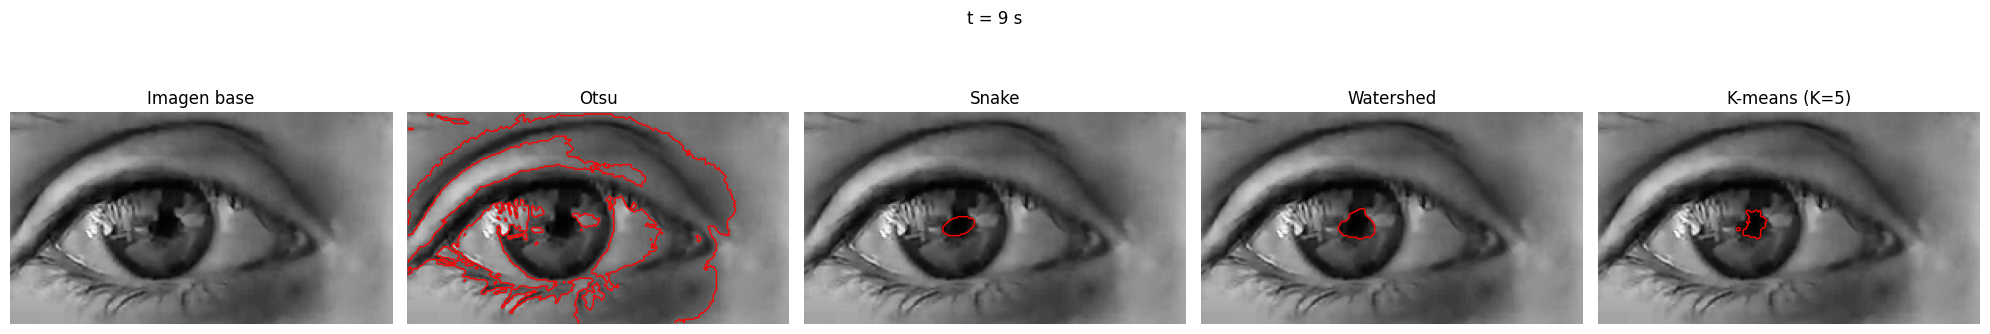

In [13]:
tiempos_anotar = [1, 3, 5, 7, 9]
resultados = {}
for t in tiempos_anotar:
    res = procesar_frame(t, cfg, raiz)
    resultados[t] = res
    if res["pupila"] is None:
        print(f"t = {t} s: no se encontró la pupila")
        continue
    mostrar_mascaras_sobre_grises(res["gris"], res["mascaras"], f"t = {t} s",
                              guardar_como=f"2_1_9_varios_sobre_grises_t{t}.png")
     